# 2. Benchmark construction: what counts as a relevant image?

**Current outcome:** `benchmark-freeze-v1` contains 871 Test images and 1,142
Development images. Eight intents use fixed map rules; unknown judgments remain
in the collection and relation controls are exploratory.

Read this notebook in three stages: **define relevance** (Sections 1–7),
**check the final inventory** (8), then **freeze the analysis** (9).
The small pilot is historical evidence; the last section verifies the current status.
No final model rankings were used to make these decisions.

## 1. What does map relevance mean?

We group source classes into forest, inland water, arable land and pasture.
Known other classes are negative for those concepts; missing or unrecognized
map information remains unknown. Relevance means agreement with these maps,
not independently verified visible truth.

Presence requires 5% of full patch area. Adjacency additionally requires both
presences and 60 m of shared four-neighbor boundary. The
[reference specification](../docs/REFERENCE_SPECIFICATION.md) explains class codes,
units and uncertainty calculations.


## 2. Which map rules do we use?

The 5%/60 m thresholds are development choices retained in the final freeze,
not optimized parameters. Each shared horizontal or vertical edge counts once;
diagonal contact does not count. Unknown cells yield conservative bounds.

This is our derived adjacency definition, not a verified reproduction of the
original BigEarthNet.txt text-generation rule. “Adjacent” does not mean “near”.


In [1]:
import json
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch

from earth_observation.archive_validation import inspect_reference_selection
from earth_observation.benchmark import (
    coverage_tables,
    freeze_blockers,
    spatial_split,
    verified_footprints,
)
from earth_observation.raster import inspect_patch, load_rgb, patch_files
from earth_observation.reference import evaluate_pilot, load_specifications

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RULES_PATH = ROOT / "config/reference-rules-v1.json"
QUERIES_PATH = ROOT / "config/query-specification-v1.json"
MANIFEST_PATH = ROOT / "manifests/data-pilot-v1.json"
CACHE = ROOT / "data/cache"
RAW = ROOT / "data/raw"
EXAMPLE_INDICES = [
    0,
    1,
    2,
]  # Fixed positions illustrating absence, threshold and contact.
DISPLAY_UPPER_DN = 3000
DESIGN_PATH = ROOT / "config/benchmark-design-v1.json"
DESIGN = json.loads(DESIGN_PATH.read_text())
EXPANSION_DESIGN_PATH = ROOT / "config/benchmark-design-v2.json"
EXPANSION_ACCESS_PATH = ROOT / "manifests/archive-data-access-v3.json"
EXPANSION_OUTPUT = ROOT / "outputs/archive-data-access-v3"
EXPANSION_CANDIDATE_PATH = ROOT / "manifests/benchmark-candidate-v4.json"
plt.rcParams["figure.dpi"] = 80
COLORS = {
    "forest": "#238b45",
    "inland_water": "#3182bd",
    "arable_land": "#fee08b",
    "pasture": "#a6d96a",
}

rules, queries = load_specifications(RULES_PATH, QUERIES_PATH)
summaries, decisions = evaluate_pilot(MANIFEST_PATH, CACHE, RAW, rules, queries)
catalog = pd.read_parquet(CACHE / "metadata.parquet")
assert decisions.shape == (10, 8)
pd.DataFrame(
    [
        {
            "concept": name,
            "source_codes": definition["codes"],
            "minimum_fraction": definition["presence_fraction"],
        }
        for name, definition in rules["classes"].items()
    ]
)

FROZEN_DESIGN_PATH = ROOT / "config/benchmark-design-v3.json"
ANALYSIS_PROTOCOL_PATH = ROOT / "config/analysis-protocol-v1.json"
FROZEN_BENCHMARK_PATH = ROOT / "manifests/benchmark-freeze-v1.json"

For these 10-m grids, each cell covers 100 m² and each full patch covers
1,440,000 m². A 5% threshold therefore means at least 72,000 m² of mapped concept
coverage. No raster has been resampled; metre units and native orientation are
validated by the reusable implementation. Unknown area remains in the denominator.

In [2]:
patch_ids = decisions.index.tolist()
area_table = pd.DataFrame(
    [
        {
            "patch": "_".join(patch_id.rsplit("_", 2)[1:]),
            "unknown_m2": summary["unknown_area_m2"],
            **{
                name + "_fraction": value["fraction_lower"]
                for name, value in summary["classes"].items()
            },
        }
        for patch_id, summary in summaries.items()
    ]
)
area_table.round(4)

,patch,unknown_m2,forest_fraction,inland_water_fraction,arable_land_fraction,pasture_fraction
0,26_57,0.0,0.4285,0.0000,0.4913,0.0801
1,27_55,0.0,0.2509,0.0424,0.7067,0.0000
2,27_56,0.0,0.8774,0.0983,0.0243,0.0000
3,27_57,0.0,0.7331,0.1073,0.0000,0.0000
4,27_58,0.0,0.5881,0.0867,0.0000,0.0000
5,27_59,0.0,0.5028,0.0849,0.0000,0.0982
6,27_60,0.0,0.7609,0.1006,0.0000,0.1072
7,27_61,0.0,0.3351,0.0394,0.0000,0.4294
8,28_55,0.0,0.3147,0.1005,0.4008,0.1840
9,28_56,0.0,0.9367,0.0453,0.0000,0.0180


All ten maps have zero unknown area and no unexpected codes. Lower and upper
bounds therefore coincide here; controlled tests, rather than this complete-map
pilot, exercise partial and missing evidence. The sample is one Austria tile and
retains the provider's `test` split. It is a technical/development inspection,
not our future held-out benchmark. These inspected patches cannot establish final
coverage or be treated as an untouched final test after selection decisions.

## 3. Which intents share one reference condition and one direct family?

Eight stable intents cover singles, conjunctions and adjacency, each with three
English formulations (24 texts, **eight intent conditions**). The forest/water
family contains its two singles, conjunction and adjacency; the arable/pasture
family has the analogous four members. Each intent belongs to exactly one family,
set before any model result. Families preserve direct dependence for later paired
statistical analysis, but two families are insufficient for a broad uncertainty
claim. No statistical resampling is implemented here.

Paraphrases express the same condition; none adds quantity, direction, distance,
or a stricter spatial assertion. Numeric thresholds define our map operationalization
and are shared by all paraphrases of the intent.

In [3]:
pd.DataFrame(
    [
        {
            "intent_id": i["intent_id"],
            "family_id": i["family_id"],
            "condition": i["kind"] + ": " + ", ".join(i["classes"]),
            "example_text": i["paraphrases"][0],
            "paraphrases": len(i["paraphrases"]),
        }
        for i in queries["intents"]
    ]
)

,intent_id,family_id,condition,example_text,paraphrases
0,single-forest,forest-water,single: forest,A satellite scene containing forest.,3
1,single-inland-water,forest-water,single: inland_water,A satellite scene containing inland water.,3
2,single-arable-land,arable-pasture,single: arable_land,A satellite scene containing arable land.,3
3,single-pasture,arable-pasture,single: pasture,A satellite scene containing pasture.,3
4,both-forest-water,forest-water,"conjunction: forest, inland_water",A satellite scene containing both forest and i...,3
5,adjacent-forest-water,forest-water,"adjacency: forest, inland_water",A satellite scene where forest is adjacent to ...,3
6,both-arable-pasture,arable-pasture,"conjunction: arable_land, pasture",A satellite scene containing both arable land ...,3
7,adjacent-arable-pasture,arable-pasture,"adjacency: arable_land, pasture",A satellite scene where arable land is adjacen...,3


## 4. Does the small pilot cover positive and negative conditions?

Evaluate every patch once per intent, retaining true/false/unknown. Count absence
of coverage explicitly. Also examine adjacency among candidates satisfying both
presence conditions: ordinary negatives caused by a missing/insufficient class
cannot demonstrate that the relation itself distinguishes scenes.

In [4]:
coverage = pd.DataFrame(
    [
        {
            "intent_id": i["intent_id"],
            "family_id": i["family_id"],
            **{
                state: int((decisions[i["intent_id"]] == state).sum())
                for state in ["true", "false", "unknown"]
            },
        }
        for i in queries["intents"]
    ]
).set_index("intent_id")
display(coverage)

relation_control_coverage = []
for family in queries["families"]:
    both = decisions["both-" + family] == "true"
    adjacent = decisions.loc[both, "adjacent-" + family]
    relation_control_coverage.append(
        {
            "family": family,
            "both_present": int(both.sum()),
            "adjacent_true": int((adjacent == "true").sum()),
            "adjacent_false": int((adjacent == "false").sum()),
            "adjacent_unknown": int((adjacent == "unknown").sum()),
        }
    )
pd.DataFrame(relation_control_coverage)

,family_id,true,false,unknown
intent_id,,,,
single-forest,forest-water,10,0,0
single-inland-water,forest-water,6,4,0
single-arable-land,arable-pasture,3,7,0
single-pasture,arable-pasture,5,5,0
both-forest-water,forest-water,6,4,0
adjacent-forest-water,forest-water,6,4,0
both-arable-pasture,arable-pasture,2,8,0
adjacent-arable-pasture,arable-pasture,2,8,0


,family,both_present,adjacent_true,adjacent_false,adjacent_unknown
0,forest-water,6,6,0,0
1,arable-pasture,2,2,0,0


Forest has ten positives and **no negative**. The other single conditions
have both states. Forest/water conjunction and adjacency each have six positives;
arable/pasture each have two. There are no unknown decisions in this complete-map
sample. Among patches passing both presences, every relation is true: **no hard
relation negative exists for either pair**. Thus this pilot cannot isolate an
adjacency failure from a presence failure. We report that limitation without
retuning thresholds to manufacture a distinction.

## 5. What do the map conditions look like beside real RGB?

The next display uses fixed pilot positions 1–3. RGB uses fixed raw DN/3000 scaling
and source NoData masks, independently of future model preprocessing. Colors on
the right display the four canonical concept masks from the reference calculation,
with known other cover in gray and unknown in white. This display aggregation
follows the explicit mapping; it does not add or interpolate reference labels.
Native projected extents and nearest-neighbor rendering preserve orientation.
Calculated percentages use full area, and boundary metres are summed cell edges.

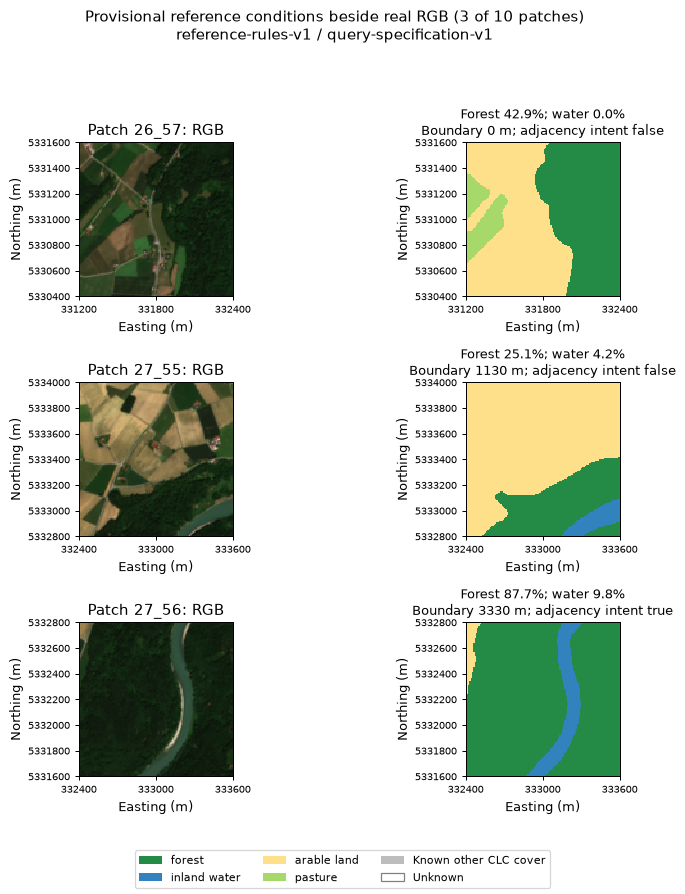

,patch,forest_fraction,water_fraction,boundary_m,adjacency_reference
0,26_57,0.428542,0.000000,0.0,false
1,27_55,0.250903,0.042431,1130.0,false
2,27_56,0.877431,0.098264,3330.0,true


In [5]:
class_names = list(rules["classes"])
cmap = ListedColormap([COLORS[name] for name in class_names] + ["#bdbdbd", "#ffffff"])
norm = BoundaryNorm(np.arange(7) - 0.5, 6)
fig, axes = plt.subplots(3, 2, figsize=(9, 10), dpi=90)
example_rows = []
for row, index in enumerate(EXAMPLE_INDICES):
    patch_id = patch_ids[index]
    summary = summaries[patch_id]
    files = patch_files(patch_id, RAW / "BigEarthNet-S2", RAW / "Reference_Maps")
    left, bottom, right, top = inspect_patch(files)["rasters"]["B04"]["bounds"]
    extent = (left, right, bottom, top)
    axes[row, 0].imshow(
        load_rgb(files, upper=DISPLAY_UPPER_DN), extent=extent, interpolation="nearest"
    )
    display_map = np.full(summary["unknown_mask"].shape, 4)
    for color_index, name in enumerate(class_names):
        display_map[summary["class_masks"][name]] = color_index
    display_map[summary["unknown_mask"]] = 5
    axes[row, 1].imshow(
        display_map, cmap=cmap, norm=norm, extent=extent, interpolation="nearest"
    )
    suffix = "_".join(patch_id.rsplit("_", 2)[1:])
    forest = summary["classes"]["forest"]["fraction_lower"]
    water = summary["classes"]["inland_water"]["fraction_lower"]
    boundary = summary["pairs"][("forest", "inland_water")]["boundary_lower_m"]
    state = decisions.loc[patch_id, "adjacent-forest-water"]
    axes[row, 0].set_title(f"Patch {suffix}: RGB")
    axes[row, 1].set_title(
        f"Forest {forest:.1%}; water {water:.1%}\n"
        f"Boundary {boundary:.0f} m; adjacency intent {state}",
        fontsize=10,
    )
    for ax in axes[row]:
        ax.set(xlabel="Easting (m)", ylabel="Northing (m)")
        ax.ticklabel_format(style="plain", useOffset=False)
        ax.tick_params(labelsize=8)
        ax.set_xticks(np.linspace(left, right, 3))
    example_rows.append(
        {
            "patch": suffix,
            "forest_fraction": forest,
            "water_fraction": water,
            "boundary_m": boundary,
            "adjacency_reference": state,
        }
    )
fig.legend(
    handles=[
        Patch(facecolor=COLORS[name], label=name.replace("_", " "))
        for name in class_names
    ]
    + [
        Patch(facecolor="#bdbdbd", label="Known other CLC cover"),
        Patch(facecolor="#ffffff", edgecolor="gray", label="Unknown"),
    ],
    loc="lower center",
    ncol=3,
    fontsize=9,
)
fig.suptitle(
    "Provisional reference conditions beside real RGB (3 of 10 patches)\n"
    "reference-rules-v1 / query-specification-v1",
    fontsize=12,
)
fig.tight_layout(rect=(0, 0.07, 1, 0.94))
(ROOT / "outputs").mkdir(exist_ok=True)
fig.savefig(ROOT / "outputs/reference-pilot-v1-examples.png", dpi=110)
plt.show()
pd.DataFrame(example_rows)

Patch 26_57 has no mapped inland water, so the forest/water intent is false.
Patch 27_55 has mapped water and 1,130 m of forest/water boundary, but water covers
only about 4.24%; its 5% presence condition fails. Patch 27_56 has about 9.83% water
and 3,330 m of mapped boundary, satisfying both presence and contact requirements.
These outcomes follow our specified thresholds, not a claim that RGB alone
proves those quantities. Visual inspection supports broad spatial correspondence: fields and woodland
in the first two scenes, and a river corridor through woodland in the third.
Smaller field boundaries and the riverbank/road corridor are more detailed in RGB
than in the map. The threshold-driven negative for patch 27_55 remains negative
even though water is visibly plausible. No visual inspection independently
verifies exact forest class membership, cover percentages or every boundary.

## 6. Which geographic evidence can we actually separate?

Country and tile names describe the source population, but do not establish
cross-tile overlap or distances. We use the verified native raster footprints,
transform densified bounds to the European metric CRS EPSG:3035, and group any
footprints whose envelope distance is **at most 2,000 m**. Connected components
include transitive chains and repeated acquisitions regardless of date. Envelopes
are conservative; grouping may retain more images together than precise polygons.
The buffer exceeds a 1,200-m patch edge and reduces immediate-neighborhood leakage;
it is not a demonstrated statistical independence distance.

All already inspected/encoded pilot IDs anchor their whole component in
**development**. Other verified components would be assigned by a fixed SHA-256
hash and 0.5 test fraction, without label-based balancing. Unverified selections
remain unassigned. Country, provider split, date or a random patch-ID split cannot
replace this spatial check.

available_images            10
countries                    1
MGRS_tiles                   1
acquisition_dates            1
identical_native_pairs       0
overlapping_native_pairs     0
spatial_components           1
development_images          10
held_out_test_images         0
dtype: int64

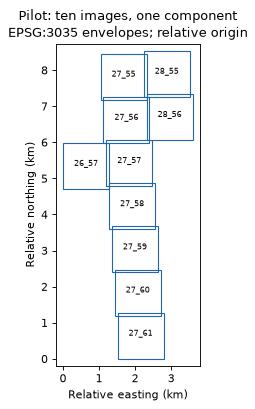

In [6]:
footprints = verified_footprints(patch_ids, RAW)
assignment = spatial_split(footprints, patch_ids, DESIGN["spatial"])
assert assignment.split.eq("development").all()
assert assignment.groupby("group_id").split.nunique().eq(1).all()
available_catalog = catalog.set_index("patch_id").loc[patch_ids]
# Native overlap audit is specific to this available single-CRS pilot.
assert footprints.native_crs.nunique() == 1
native_boxes = footprints.native_bounds.tolist()
identical_pairs = sum(a == b for a, b in combinations(native_boxes, 2))
overlapping_pairs = sum(
    max(a[0], b[0]) < min(a[2], b[2]) and max(a[1], b[1]) < min(a[3], b[3])
    for a, b in combinations(native_boxes, 2)
)
geography = pd.Series(
    {
        "available_images": len(patch_ids),
        "countries": available_catalog.country.nunique(),
        "MGRS_tiles": footprints.tile.nunique(),
        "acquisition_dates": footprints.date.nunique(),
        "identical_native_pairs": identical_pairs,
        "overlapping_native_pairs": overlapping_pairs,
        "spatial_components": assignment.group_id.nunique(),
        "development_images": int(assignment.split.eq("development").sum()),
        "held_out_test_images": int(assignment.split.eq("test").sum()),
    }
)
display(geography)
fig_geo, ax = plt.subplots(figsize=(6, 5), constrained_layout=True)
origin_x, origin_y = footprints.left.min(), footprints.bottom.min()
for pid, row in footprints.iterrows():
    ax.add_patch(
        plt.Rectangle(
            ((row.left - origin_x) / 1000, (row.bottom - origin_y) / 1000),
            (row.right - row.left) / 1000,
            (row.top - row.bottom) / 1000,
            fill=False,
            edgecolor="#2166ac",
        )
    )
    ax.text(
        ((row.left + row.right) / 2 - origin_x) / 1000,
        ((row.bottom + row.top) / 2 - origin_y) / 1000,
        "_".join(pid.split("_")[-2:]),
        ha="center",
        fontsize=7,
    )
ax.set_xlim(-0.2, (footprints.right.max() - origin_x) / 1000 + 0.2)
ax.set_ylim(-0.2, (footprints.top.max() - origin_y) / 1000 + 0.2)
ax.set_aspect("equal")
ax.set_xlabel("Relative easting (km)")
ax.set_ylabel("Relative northing (km)")
ax.set_title("Pilot: ten images, one component\nEPSG:3035 envelopes; relative origin")
plt.show()

All ten verified images lie in one connected component, one Austria tile and one
acquisition date, with zero identical native footprints or positive-area
native overlaps. Immediate neighbors still share landscape context. Moving any of these images to a final test set would split the
same development landscape across stages. The geographic diagram displays
projected bounding envelopes, not a more accurate land-cover map.

### 6.1 How do intent families and relation controls change the counts?

Families summarize **patch × intent decisions**, not independent images or
paraphrases. Every intent uses all ten main candidates. The controls below are
separate, explicitly filtered additional experiments: both class-presence
conditions must be true. Missing classes are not false spatial relations.
Unknown presence is reported outside eligibility; unknown relation remains
inside an eligible control. Unknown source causes are counted separately because
unknown pixels do not always make an intent undecidable.

In [7]:
intent_coverage, family_coverage, relation_coverage, control_ids = coverage_tables(
    decisions, queries, assignment.group_id
)
display(intent_coverage)
display(
    family_coverage.assign(
        countries=geography["countries"],
        spatial_components=geography["spatial_components"],
    )
)
display(relation_coverage)

,family_id,true,false,unknown,judged_fraction,spatial_groups,positive_groups,negative_groups,positive_outside_largest_group,negative_outside_largest_group
intent_id,,,,,,,,,,
single-forest,forest-water,10,0,0,1.0,1,1,0,0,0
single-inland-water,forest-water,6,4,0,1.0,1,1,1,0,0
single-arable-land,arable-pasture,3,7,0,1.0,1,1,1,0,0
single-pasture,arable-pasture,5,5,0,1.0,1,1,1,0,0
both-forest-water,forest-water,6,4,0,1.0,1,1,1,0,0
adjacent-forest-water,forest-water,6,4,0,1.0,1,1,1,0,0
both-arable-pasture,arable-pasture,2,8,0,1.0,1,1,1,0,0
adjacent-arable-pasture,arable-pasture,2,8,0,1.0,1,1,1,0,0


,true,false,unknown,patch_intent_count,judged_fraction,unique_images,countries,spatial_components
family_id,,,,,,,,
forest-water,28,12,0,40,1.0,10,1,1
arable-pasture,12,28,0,40,1.0,10,1,1


,family_id,both_present,missing_class,unknown_presence,true,false,unknown,judged_fraction,spatial_groups,true_outside_largest_group,false_outside_largest_group
intent_id,,,,,,,,,,,
adjacent-forest-water,forest-water,6,4,0,6,0,0,1.0,1,0,0
adjacent-arable-pasture,arable-pasture,2,8,0,2,0,0,1.0,1,0,0


The forest/water family has 28 positive and 12 negative patch-intent decisions;
arable/pasture has 12 and 28. Each family still sees only **ten unique images** in
one geographic component. All source masks/configured unknown codes/unrecognized
codes count zero here; all intent judgments are known. Controlled tests exercise
unknown source causes and ambiguous states, rather than inventing them in this
complete-map pilot. The six forest/water and two arable/pasture control candidates
have zero false relations. After removing the largest positive component,
**zero positives remain for every intent**.

## 7. What did the original pilot lack?

The historical design required enough positive and negative examples and
spatial dispersion. Its relation controls also required hard negatives:
both classes present, but no qualifying contact. The pilot failed these gates.

The final inventory preserves that evidence. Section 9 documents the later explicit
revision for unknown references and exploratory controls; the old failure
checks below intentionally still evaluate the original design.


In [8]:
development_failures = freeze_blockers(
    intent_coverage, relation_coverage, DESIGN["coverage"], 0, queries
)
display(pd.DataFrame({"development_gate_failure": development_failures}))
print("Historical pilot failures: no held-out Test coverage at this stage.")

,development_gate_failure
0,single-forest: candidate count 10 < 20
1,single-forest: negatives 0 < 10
2,single-forest: positive dispersion 0 < 10
3,single-forest: spatial groups 1 < 3
4,single-inland-water: candidate count 10 < 20
5,single-inland-water: positives 6 < 10
6,single-inland-water: negatives 4 < 10
7,single-inland-water: positive dispersion 0 < 10
8,single-inland-water: spatial groups 1 < 3
9,single-arable-land: candidate count 10 < 20


Historical pilot failures: no held-out Test coverage at this stage.


## 8. Does one fixed 2,000-ID expansion support map-agreement retrieval?

**Authorized design revision: benchmark-design-v2.** Main relevance means
agreement with generalized CLC2018 categories under unchanged 5% presence and
60-m summed four-neighbor mapped contact. Adjacency is a property of the mapped
regions; it is not independently verified adjacency of visible objects. Native
10-m raster resolution does not improve the underlying 25-ha/100-m mapping
conventions. RGB/map differences remain qualitative Development diagnostics.

Missing original captions no longer block image/query retrieval when image
identity, provenance, geometry and map evidence are independently verified.
Original-caption analyses can only use actual original annotations. Missing text
is not missing map evidence and never becomes a false reference judgment.
All numerical coverage, spatial grouping and analysis policies remain unchanged.


In [9]:
from earth_observation.benchmark_expansion import (
    load_expanded_benchmark,
    verify_design_revision,
)

expanded_design = json.loads(EXPANSION_DESIGN_PATH.read_text())
verify_design_revision(expanded_design, DESIGN)
expanded_access = json.loads(EXPANSION_ACCESS_PATH.read_text())
expanded_record = load_expanded_benchmark(
    EXPANSION_CANDIDATE_PATH, ROOT, require_frozen=False
)
expanded_completion = json.loads((EXPANSION_OUTPUT / "completion.json").read_text())
expanded_plan = pd.read_csv(ROOT / expanded_access["selection_file"])
previous_plan = pd.read_csv(ROOT / "manifests/coverage-selection-v1.csv")
assert len(expanded_plan) == 2000
for country in previous_plan.country.unique():
    assert (
        previous_plan.loc[previous_plan.country.eq(country), "patch_id"].tolist()
        == expanded_plan.loc[expanded_plan.country.eq(country), "patch_id"]
        .head(25)
        .tolist()
    )
display(
    expanded_plan.groupby("country").agg(
        planned=("patch_id", "size"), tiles=("tile", "nunique")
    )
)

,planned,tiles
country,,
Austria,200,7
Belgium,200,3
Finland,200,21
Ireland,200,5
Kosovo,200,1
Lithuania,200,7
Luxembourg,200,1
Portugal,200,3
Serbia,200,6


### 8.1 What changed in sampling and source availability?

Quota increases from 25 to 200 in each country. The same SHA-256 seed and tile
round-robin naturally preserve each old country prefix, so no fallback sampling
rule is required. Global ranks shift as country blocks grow; all 250 old IDs are
retained. The fixed 2,000-ID plan was saved before new map labels were inspected.
Country quotas remain enrichment, not representative population sampling.

One sequential scan of each already local verified archive extracted 7,000 new
TIFFs and reused 1,000: 177,196,674 selected bytes, of which 155,046,370 are new
native files. Both amounts are below the 256-MiB additional budget. No archive,
text, weight or other dataset transfer occurred. This is exactly one expansion,
not repeated drawing until coverage passes.


In [10]:
expanded_sources = pd.read_csv(EXPANSION_OUTPUT / "source-checks.csv").set_index(
    "patch_id"
)
assert expanded_sources.index.tolist() == expanded_plan.patch_id.tolist()
assert expanded_sources.technical_status.eq("verified").all()
display(
    pd.DataFrame(
        [
            {
                "inventory": "Planned expansion",
                "planned": 2000,
                "technical": 2000,
                "original_text_verified": 241,
                "original_text_source_absent": 9,
                "original_text_not_requested": 1750,
            },
            {
                "inventory": "Earlier Development",
                "planned": 13,
                "technical": 13,
                "original_text_verified": 13,
                "original_text_source_absent": 0,
                "original_text_not_requested": 0,
            },
        ]
    ).set_index("inventory")
)
print("Native CRS count:", expanded_sources.crs.nunique())
print(
    "Native RGB DN range:",
    expanded_sources.rgb_valid_min_dn.min(),
    expanded_sources.rgb_valid_max_dn.max(),
)

,planned,technical,original_text_verified,original_text_source_absent,original_text_not_requested
inventory,,,,,
Planned expansion,2000,2000,241,9,1750
Earlier Development,13,13,13,0,0


Native CRS count: 7
Native RGB DN range: 1 17888


### 8.2 Does the computation agree with the map's categorical meaning?

Choose the first currently Development-assigned planned ID in each predeclared
country Austria, Belgium and Finland, without class or ranking criteria. Raw CLC
pixel counts reproduce the grouped class areas using the entire 144-ha patch as
denominator. CLC 243/324 and urban/other cover remain known other, rather than
unknown because the queries omit them. Contact counts mapped shared edges once;
diagonal contacts and boundaries outside the patch contribute no metres.

The existing hand-computed reference tests check these edge conventions and
unknown bounds. The following raw-count/fraction table and native map/RGB views
check the actual source interpretation. They establish operational map agreement,
not visual truth or equivalence to original text-generator rules.


,country,raw_clc_pixel_counts,full_patch_area_m2,mapped_fractions,mapped_contact_m
0,Austria,"{'211': 5565, '243': 5182, '311': 3653}",1440000.0,"{'forest': 0.2536805555555556, 'inland_water':...","{'arable_land|pasture': 0.0, 'forest|inland_wa..."
1,Belgium,"{'112': 878, '211': 10739, '231': 2721, '242':...",1440000.0,"{'forest': 0.0, 'inland_water': 0.0, 'arable_l...","{'arable_land|pasture': 2710.0, 'forest|inland..."
2,Finland,"{'243': 8034, '312': 1627, '313': 3115, '324':...",1440000.0,"{'forest': 0.3293055555555556, 'inland_water':...","{'arable_land|pasture': 0.0, 'forest|inland_wa..."


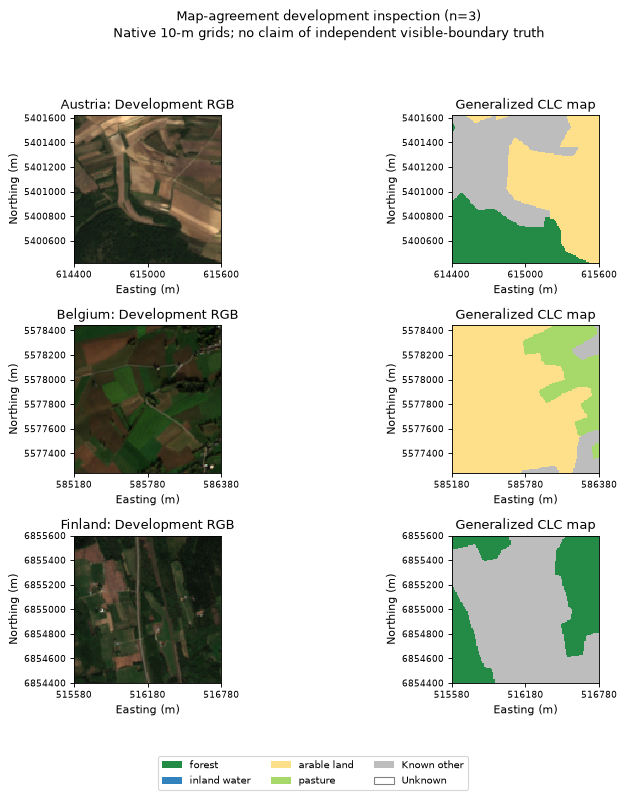

In [11]:
semantic_examples = expanded_completion["reference_validation"]["development_examples"]
display(
    pd.DataFrame(semantic_examples)[
        [
            "country",
            "raw_clc_pixel_counts",
            "full_patch_area_m2",
            "mapped_fractions",
            "mapped_contact_m",
        ]
    ]
)
expanded_example_ids = [row["patch_id"] for row in semantic_examples]
_, _, expanded_example_summaries = inspect_reference_selection(
    {
        "members": [
            member
            for receipt in json.loads(
                (CACHE / "archive-access-v3/extraction-results.json").read_text()
            )
            if receipt["archive"]["name"] == "Reference_Maps.tar.zst"
            for member in receipt["members"]
            if any("/" + pid + "/" in member["name"] for pid in expanded_example_ids)
        ]
    },
    expanded_example_ids,
    RAW,
    rules,
    queries,
)
fig_expanded, expanded_axes = plt.subplots(3, 2, figsize=(10, 10), dpi=80)
for row, pid in enumerate(expanded_example_ids):
    summary = expanded_example_summaries[pid]
    files = patch_files(pid, RAW / "BigEarthNet-S2", RAW / "Reference_Maps")
    native = inspect_patch(files)["rasters"]["B04"]
    left, bottom, right, top = native["bounds"]
    extent = (left, right, bottom, top)
    expanded_axes[row, 0].imshow(
        load_rgb(files, upper=DISPLAY_UPPER_DN),
        extent=extent,
        interpolation="nearest",
    )
    display_map = np.full(summary["unknown_mask"].shape, 4)
    for index, name in enumerate(class_names):
        display_map[summary["class_masks"][name]] = index
    display_map[summary["unknown_mask"]] = 5
    expanded_axes[row, 1].imshow(
        display_map,
        extent=extent,
        cmap=cmap,
        norm=norm,
        interpolation="nearest",
    )
    expanded_axes[row, 0].set_title(
        semantic_examples[row]["country"] + ": Development RGB"
    )
    expanded_axes[row, 1].set_title("Generalized CLC map")
    for axis in expanded_axes[row]:
        axis.set_xlabel("Easting (m)")
        axis.set_ylabel("Northing (m)")
        axis.ticklabel_format(style="plain", useOffset=False)
        axis.set_xticks(np.linspace(left, right, 3))
        axis.tick_params(labelsize=8)
fig_expanded.legend(
    handles=[
        Patch(facecolor=COLORS[name], label=name.replace("_", " "))
        for name in class_names
    ]
    + [
        Patch(facecolor="#bdbdbd", label="Known other"),
        Patch(facecolor="#ffffff", edgecolor="gray", label="Unknown"),
    ],
    loc="lower center",
    ncol=3,
    fontsize=9,
)
fig_expanded.suptitle(
    "Map-agreement development inspection (n=3)\n"
    "Native 10-m grids; no claim of independent visible-boundary truth"
)
fig_expanded.tight_layout(rect=(0, 0.08, 1, 0.94))
fig_expanded.savefig(EXPANSION_OUTPUT / "development-rgb-map.png", dpi=110)
plt.show()

**Observed Development views:** Austria shows broad woodland and agricultural
regions, while individual field strips are generalized into CLC 243 known-other
cover. Belgium's mapped arable/pasture boundary is 2,710 m (271 native shared
edges); RGB alone does not independently verify those land-use categories.
Finland's gray CLC 243/324 region includes vegetation as well as fields, and is
known other rather than missing information. The examples support the narrower
map-agreement interpretation without correcting any map or rule.

### 8.3 How did new neighbors change the spatial structure?

All 128 previously Development-assigned images remain there. The enlarged graph
has 11 groups that merge multiple earlier groups; 86 prior images change group
identity or provisional split, including 32 former Test-side images now in
Development. No prior Development image moves into Test. Assignment changes
follow new graph connectivity and the original anchored/hash rule, not labels.
Coincident native footprints at different acquisition dates are grouped together.


,development,test
Austria,121,92
Belgium,117,83
Finland,84,116
Ireland,126,74
Kosovo,165,35
Lithuania,109,91
Luxembourg,123,77
Portugal,100,100
Serbia,95,105
Switzerland,102,98


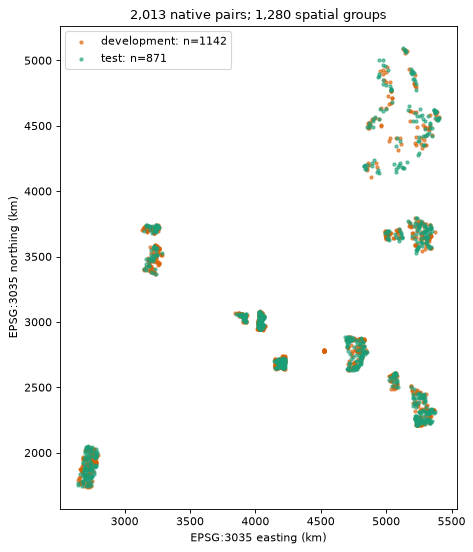

In [12]:
expanded_assignments = pd.DataFrame(expanded_record["spatial_inventory"]).set_index(
    "patch_id"
)
display(pd.DataFrame(expanded_completion["country_split_counts"]).T)
fig_expansion_space, ax_expansion_space = plt.subplots(figsize=(8, 7))
for split, color in [("development", "#d95f02"), ("test", "#1b9e77")]:
    positions = expanded_assignments[expanded_assignments.split.eq(split)]
    ax_expansion_space.scatter(
        (positions.left + positions.right) / 2000,
        (positions.bottom + positions.top) / 2000,
        s=8,
        alpha=0.6,
        color=color,
        label=f"{split}: n={len(positions)}",
    )
ax_expansion_space.set_xlabel("EPSG:3035 easting (km)")
ax_expansion_space.set_ylabel("EPSG:3035 northing (km)")
ax_expansion_space.set_title("2,013 native pairs; 1,280 spatial groups")
ax_expansion_space.set_aspect("equal")
ax_expansion_space.legend()
fig_expansion_space.tight_layout()
fig_expansion_space.savefig(EXPANSION_OUTPUT / "spatial-structure.png", dpi=110)
plt.show()

### 8.4 Which unchanged gates pass, and which still fail?

There are 1,142 Development images and 871 Test-side images. Every intent now has
at least ten positive/negative Test references and sufficient positive spatial
spread. That closes the earlier positive-count gap. Main unknown map decisions
remain: two arable, and three water/pasture/composite decisions. Their judged
fractions are below the required 1.0. Missing captions are not these unknowns.

Separate Test controls contain 35 true / 2 false forest-water relations and
59 true / 7 false arable-pasture relations, with zero unknown relation states
inside both-present controls. Required false count is ten; deficits are eight
and three. Forest-water has only one false case outside its largest negative
group, below five. Arable-pasture false dispersion is six and passes.
No unknown is set false, no incomplete references are silently pruned, and
no further sample is drawn.


In [13]:
for split in ["all", "test"]:
    print(f"Main map agreement — {split}")
    display(pd.DataFrame(expanded_completion["coverage"][split]["intent"]))
    print(f"Separate both-present relation controls — {split}")
    display(pd.DataFrame(expanded_completion["coverage"][split]["relations"]))
display(pd.DataFrame(expanded_completion["unknown_reference_decisions"]))
display(pd.DataFrame({"failed_gate": expanded_completion["blockers"]}))
assert expanded_record["status"] == "blocked-not-frozen"
try:
    load_expanded_benchmark(EXPANSION_CANDIDATE_PATH, ROOT)
except ValueError as error:
    print("Final evaluation remains prohibited:", error)

Main map agreement — all


,intent_id,family_id,true,false,unknown,judged_fraction,spatial_groups,positive_groups,negative_groups,positive_outside_largest_group,negative_outside_largest_group
0,single-forest,forest-water,1211,801,1,0.999503,1280,776,575,1180,779
1,single-inland-water,forest-water,126,1883,4,0.998013,1280,108,1203,120,1830
2,single-arable-land,arable-pasture,801,1209,3,0.998510,1280,539,807,783,1174
3,single-pasture,arable-pasture,543,1466,4,0.998013,1280,322,1026,523,1415
4,both-forest-water,forest-water,80,1929,4,0.998013,1280,71,1226,74,1876
5,adjacent-forest-water,forest-water,74,1935,4,0.998013,1280,66,1229,68,1882
6,both-arable-pasture,arable-pasture,183,1826,4,0.998013,1280,128,1188,172,1773
7,adjacent-arable-pasture,arable-pasture,160,1849,4,0.998013,1280,113,1199,150,1796


Separate both-present relation controls — all


,intent_id,family_id,both_present,missing_class,unknown_presence,true,false,unknown,judged_fraction,spatial_groups,true_outside_largest_group,false_outside_largest_group
0,adjacent-forest-water,forest-water,80,1929,4,74,6,0,1.0,71,68,5
1,adjacent-arable-pasture,arable-pasture,183,1826,4,160,23,0,1.0,128,150,22


Main map agreement — test


...

Separate both-present relation controls — test


,intent_id,family_id,both_present,missing_class,unknown_presence,true,false,unknown,judged_fraction,spatial_groups,true_outside_largest_group,false_outside_largest_group
0,adjacent-forest-water,forest-water,37,831,3,35,2,0,1.0,35,33,1
1,adjacent-arable-pasture,arable-pasture,66,802,3,59,7,0,1.0,48,53,6


,patch_id,split,unknown_area_m2,unknown_fraction,unexpected_codes,masked_pixels
0,S2B_MSIL2A_20170924T093019_N9999_R136_T36VVQ_1...,test,103300.0,0.071736,[],0
1,S2B_MSIL2A_20170716T093039_N9999_R136_T36VVR_0...,test,236700.0,0.164375,[],0
2,S2B_MSIL2A_20170718T115359_N9999_R023_T29UPB_1...,development,304900.0,0.211736,[],0
3,S2A_MSIL2A_20180507T093041_N9999_R136_T35UMA_1...,test,181900.0,0.126319,[],0


,failed_gate
0,single-inland-water: judged fraction 0.9965556...
1,single-arable-land: judged fraction 0.99770378...
2,single-pasture: judged fraction 0.996555683122...
3,both-forest-water: judged fraction 0.996555683...
4,adjacent-forest-water: judged fraction 0.99655...
5,both-arable-pasture: judged fraction 0.9965556...
6,adjacent-arable-pasture: judged fraction 0.996...
7,adjacent-forest-water: relation false 2 below ...
8,adjacent-forest-water: false dispersion 1 belo...
9,adjacent-arable-pasture: relation false 7 belo...


Final evaluation remains prohibited: Benchmark is blocked, not frozen; final evaluation is prohibited


### 8.5 Why did the larger collection still need a protocol decision?

The fixed expansion now provides enough positive/negative main examples and
spatial dispersion. A few unknown judgments and sparse relation negatives
still fail the old full-judgeability/confirmatory-control requirements.

Rather than silently removing images or relaxing thresholds, Section 9 records
an explicit analysis revision. The 2,000-ID selection and reference rules stay
unchanged. No further sampling follows these failures.


## 9. What was frozen before model evaluation?

The final protocol keeps all 871 Test images and all eight intents. Unknown
judgments receive metric bounds; the sparse relation controls are exploratory.
Original captions are optional because models use images and our fixed queries.

The validator checks source identity, native geometry, relevance and coverage.
The revised freeze does not turn earlier blocked candidates into valid ones.


In [14]:
from earth_observation.analysis_protocol import (
    load_frozen_benchmark,
    validate_analysis_revision,
)

frozen_design = json.loads(FROZEN_DESIGN_PATH.read_text())
analysis_protocol = json.loads(ANALYSIS_PROTOCOL_PATH.read_text())
validate_analysis_revision(frozen_design, expanded_design, analysis_protocol)
frozen_record = load_frozen_benchmark(FROZEN_BENCHMARK_PATH, ROOT)
readiness = frozen_record["analysis_readiness"]
assert frozen_record["status"] == "frozen" and not readiness["blockers"]
assert frozen_record["main_candidates"] == expanded_record["main_candidates"]
assert frozen_record["relevance"] == expanded_record["relevance"]
reference_coverage = pd.DataFrame(readiness["reference_coverage"])
display(reference_coverage)
print("Frozen inventory: Development 1,142; Test 871; groups 1,280")
print("No final ranking metrics computed; specification and readiness only")

,intent_id,known_true,known_false,unknown,candidates,judged_fraction,assignments,ap_defined_for_all_completions,output
0,single-forest,549,322,0,871,1.000000,1,True,exact-value
1,single-inland-water,62,806,3,871,0.996556,8,True,reference-uncertainty-interval
2,single-arable-land,350,519,2,871,0.997704,4,True,reference-uncertainty-interval
3,single-pasture,218,650,3,871,0.996556,8,True,reference-uncertainty-interval
4,both-forest-water,37,831,3,871,0.996556,8,True,reference-uncertainty-interval
5,adjacent-forest-water,35,833,3,871,0.996556,8,True,reference-uncertainty-interval
6,both-arable-pasture,66,802,3,871,0.996556,8,True,reference-uncertainty-interval
7,adjacent-arable-pasture,59,809,3,871,0.996556,8,True,reference-uncertainty-interval


Frozen inventory: Development 1,142; Test 871; groups 1,280
No final ranking metrics computed; specification and readiness only


### 9.2 How do unknown references enter the analysis?

Enumerate possible binary labels for an intent's unknown images. Known labels
and rankings stay fixed. Share each assignment across models and paraphrases;
average formulations and compute paired differences before taking extrema.

AP's positive denominator changes with the assignment. The example below shows
why assigning all unknowns zero or one does not always find its extrema.
Reference bounds are not confidence intervals. Across intents, averaged bounds
are conservative envelopes because logical constraints may couple labels.
[The protocol](../docs/ANALYSIS_PROTOCOL.md) records the complete equations.


In [15]:
# Hand-computed specification example, not a final retrieval calculation.
ap_example = pd.DataFrame(
    {
        "ranking": ["[?, 0, 1, ?]"] * 4,
        "unknown assignment": ["(0, 0)", "(0, 1)", "(1, 0)", "(1, 1)"],
        "AP (exact fraction)": ["1/3", "5/12", "5/6", "29/36"],
    }
)
display(ap_example)
display(
    pd.DataFrame(readiness["exploratory_relations"])[
        [
            "intent_id",
            "true",
            "false",
            "unknown",
            "spatial_groups",
            "true_outside_largest_group",
            "false_outside_largest_group",
        ]
    ]
)

,ranking,unknown assignment,AP (exact fraction)
0,"[?, 0, 1, ?]","(0, 0)",1/3
1,"[?, 0, 1, ?]","(0, 1)",5/12
2,"[?, 0, 1, ?]","(1, 0)",5/6
3,"[?, 0, 1, ?]","(1, 1)",29/36


,intent_id,true,false,unknown,spatial_groups,true_outside_largest_group,false_outside_largest_group
0,adjacent-forest-water,35,2,0,35,33,1
1,adjacent-arable-pasture,59,7,0,48,53,6


### 9.3 Findings and next stage

**The benchmark is frozen:** 871 Test images in 637 groups and 1,142 Development
images in 643 groups. All previously inspected Development images remain there.
Every main intent has enough known positives/negatives and spatial dispersion;
unknown counts are zero, two or three per intent.

The reference is generalized map agreement. The two relation controls have only
two and seven negative cases, so they remain exploratory. Captions do not filter
the image pool. No model results informed the protocol revision.

[Notebook 03](03_retrieval_evaluation.ipynb) evaluates the frozen models and
separates reference ambiguity, wording variation and inference limits.
